<a href="https://colab.research.google.com/github/swarupe/da232o-assignment-1/blob/main/DA232o_Assignment_1_Swarup_E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: object detection preceded by a pre-trained model

YOLOv8n with a frozen DINOv2 in front, trained and compared against plain YOLOv8n on PASCAL VOC2007.

Environment (Python 3.11): `pip install torch==2.8.0 torchvision==0.23.0 --index-url https://download.pytorch.org/whl/cu128`,
then `pip install ultralytics==8.4.157 transformers==4.57.1 pandas jupyterlab ipywidgets`.

## 1. Setup

In [ ]:
import copy, csv, hashlib, json, os, random, shutil, statistics, sys, tarfile, time, urllib.request
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from pathlib import Path
os.environ["YOLO_VERBOSE"] = "False"  # keep Ultralytics' progress bars out of the notebook

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import ultralytics
import yaml
from IPython.display import display
from PIL import Image
from torch import nn
from torch.utils.flop_counter import FlopCounterMode
from transformers import Dinov2Model
from ultralytics import YOLO
from ultralytics.nn import tasks
from ultralytics.utils.metrics import compute_ap

QUICK = False              # True: 1 epoch run of the whole pipeline to test
OUT_NAME = "outputs"      # where runs, evaluations and figures are written

REPO = Path.cwd()
DATA = REPO / "data"
VOC = DATA / "VOC2007"
OUT = Path(OUT_NAME) if Path(OUT_NAME).is_absolute() else REPO / OUT_NAME
for d in ("runs", "evals", "figures", "cfg", "folds"):
    (OUT / d).mkdir(parents=True, exist_ok=True)


NAMES = ["aeroplane", "bicycle", "bird", "boat", "bottle", "bus", "car", "cat", "chair", "cow", "diningtable",
         "dog", "horse", "motorbike", "person", "pottedplant", "sheep", "sofa", "train", "tvmonitor"]
DINO_ID, DINO_REVISION = "facebook/dinov2-small", "ed25f3a31f01632728cabb09d1542f84ab7b0056"
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
VAL_KW = dict(imgsz=640, batch=16, conf=0.001, iou=0.7, plots=False, verbose=False)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

COLOR = {"baseline": "#2a78d6", "dino": "#eb6834", "blind": "#1baf7a", "pretrained": "#eda100"}
INK, MUTED, GRID, NEG = "#1f1f1e", "#6b6b68", "#e6e5e1", "#e34948"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "axes.axisbelow": True})

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def save_fig(fig, name):
    fig.tight_layout(); fig.savefig(OUT / "figures" / name, dpi=150); plt.show()

print("torch", torch.__version__, "| ultralytics", ultralytics.__version__, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("outputs ->", OUT, "| QUICK =", QUICK)

torch 2.8.0+cu128 | ultralytics 8.4.157 | NVIDIA GeForce RTX 4070 Laptop GPU
outputs -> /home/swarup/mtech-course/intelligent-user-interface/assignment-1-object-detection/outputs | QUICK = False


## 2. Data: PASCAL VOC2007

In [ ]:
# Official archives (pjreddie.com mirror), checked against the MD5s torchvision.datasets.VOCDetection uses.
ARCHIVES = {"VOCtrainval_06-Nov-2007.tar": "c52e279531787c972589f7e41ab4ae64",
            "VOCtest_06-Nov-2007.tar": "b6e924de25625d8de591ea690078ad9f"}
RAW = VOC / "raw"
DEVKIT = RAW / "VOCdevkit" / "VOC2007"
RAW.mkdir(parents=True, exist_ok=True)
if not (DEVKIT / "ImageSets/Main/test.txt").exists():
    for name, expected in ARCHIVES.items():
        tar = RAW / name
        if not tar.exists() or md5(tar) != expected:
            req = urllib.request.Request(f"https://pjreddie.com/media/files/{name}", headers={"User-Agent": "curl/8"})
            with urllib.request.urlopen(req) as r, open(tar, "wb") as f:
                shutil.copyfileobj(r, f, 1 << 20)
        assert md5(tar) == expected, f"{name}: checksum mismatch"
        with tarfile.open(tar) as t:
            t.extractall(RAW, filter="data")
print({name: md5(RAW / name) == h for name, h in ARCHIVES.items()})

{'VOCtrainval_06-Nov-2007.tar': True, 'VOCtest_06-Nov-2007.tar': True}


In [ ]:
def convert_box(size, box):
    # VOC corners (xmin, xmax, ymin, ymax), 1-based pixels -> YOLO (x_centre, y_centre, width, height), 0-1
    dw, dh = 1.0 / size[0], 1.0 / size[1]
    x, y = (box[0] + box[1]) / 2.0 - 1, (box[2] + box[3]) / 2.0 - 1
    return x * dw, y * dh, (box[1] - box[0]) * dw, (box[3] - box[2]) * dh

def parse(image_id):
    root = ET.parse(DEVKIT / "Annotations" / f"{image_id}.xml").getroot()
    w, h = int(root.find("size/width").text), int(root.find("size/height").text)
    objs = []
    for o in root.iter("object"):
        b = o.find("bndbox")
        objs.append((o.find("name").text, o.find("difficult").text == "1",
                     [float(b.find(k).text) for k in ("xmin", "xmax", "ymin", "ymax")]))
    return w, h, objs

for split in ("trainval", "test"):
    (VOC / "images" / split).mkdir(parents=True, exist_ok=True)
    (VOC / "labels" / split).mkdir(parents=True, exist_ok=True)
    for i in (DEVKIT / "ImageSets/Main" / f"{split}.txt").read_text().split():
        dst = VOC / "images" / split / f"{i}.jpg"
        if not dst.exists():
            shutil.copy2(DEVKIT / "JPEGImages" / f"{i}.jpg", dst)
        w, h, objs = parse(i)
        lines = [" ".join(str(v) for v in (NAMES.index(c), *convert_box((w, h), box))) for c, difficult, box in objs if not difficult]
        (VOC / "labels" / split / f"{i}.txt").write_text("\n".join(lines) + ("\n" if lines else ""))
print({s: len(list((VOC / "images" / s).glob("*.jpg"))) for s in ("trainval", "test")})

{'trainval': 5011, 'test': 4952}


,class,difficult,VOC corners,YOLO line
0,chair,False,"[263.0, 324.0, 211.0, 339.0]",8 0.5850 0.7307 0.1220 0.3413
1,chair,False,"[165.0, 253.0, 264.0, 372.0]",8 0.4160 0.8453 0.1760 0.2880
2,chair,True,"[5.0, 67.0, 244.0, 374.0]",NaN
3,chair,False,"[241.0, 295.0, 194.0, 299.0]",8 0.5340 0.6547 0.1080 0.2800
4,chair,True,"[277.0, 312.0, 186.0, 220.0]",NaN


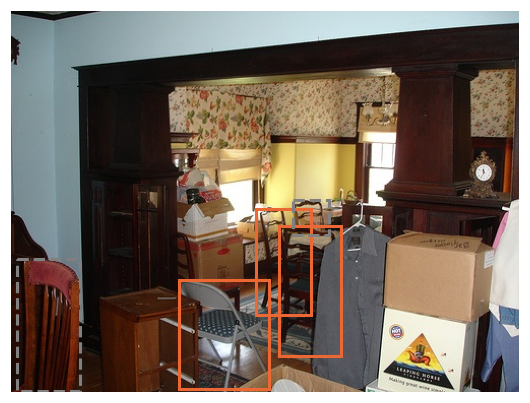

In [ ]:
# One annotation, before and after conversion. Grey dashed = "difficult", dropped from the labels.
w, h, objs = parse("000005")
display(pd.DataFrame([{"class": c, "difficult": d, "VOC corners": box,
                       "YOLO line": None if d else f"{NAMES.index(c)} " + " ".join(f"{v:.4f}" for v in convert_box((w, h), box))}
                      for c, d, box in objs]))
fig, ax = plt.subplots(figsize=(6, 4.5)); ax.imshow(Image.open(VOC / "images/trainval/000005.jpg")); ax.axis("off")
for c, d, (x0, x1, y0, y1) in objs:
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=2, color="grey" if d else COLOR["dino"], ls="--" if d else "-"))
plt.show()

,trainval,test
images,5011,4952
objects kept,12608,12032
difficult dropped,3054,2944


exact duplicate groups in trainval: [['000338', '007284'], ['000949', '005042'], ['008037', '009623']]


files shared by trainval and test: 0


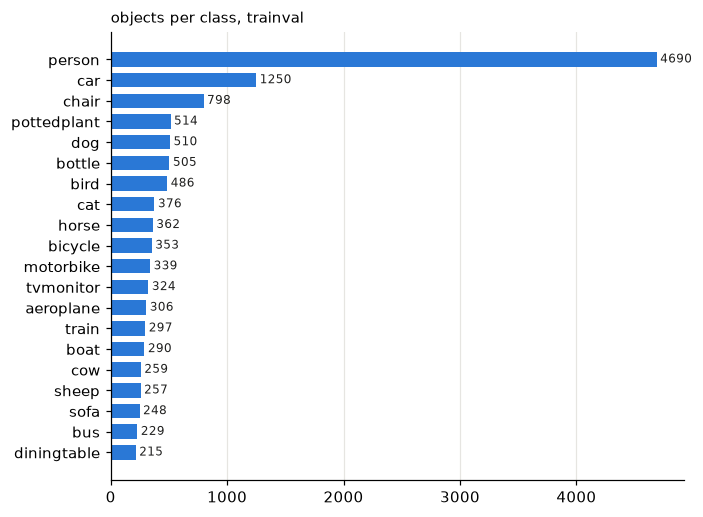

In [ ]:
# Profile: counts, difficult objects, class balance, exact duplicates.
profile = {}
for split in ("trainval", "test"):
    kept, dropped = Counter(), 0
    for i in (DEVKIT / "ImageSets/Main" / f"{split}.txt").read_text().split():
        for c, d, _ in parse(i)[2]:
            dropped += d
            kept[c] += not d
    profile[split] = {"images": len(list((VOC / "images" / split).glob("*.jpg"))), "objects kept": sum(kept.values()),
                      "difficult dropped": dropped, "per class": kept}
display(pd.DataFrame({s: {k: v for k, v in p.items() if k != "per class"} for s, p in profile.items()}))

hashes = defaultdict(list)
for p in sorted((VOC / "images/trainval").glob("*.jpg")):
    hashes[md5(p)].append(p)
print("exact duplicate groups in trainval:", [[p.stem for p in g] for g in hashes.values() if len(g) > 1])
print("files shared by trainval and test:", len(set(hashes) & {md5(p) for p in (VOC / "images/test").glob("*.jpg")}))

counts = pd.Series(profile["trainval"]["per class"]).reindex(NAMES).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.barh(counts.index, counts.values, color=COLOR["baseline"], height=0.7); ax.grid(axis="y", visible=False)
for y, v in enumerate(counts.values):
    ax.text(v + 30, y, v, va="center", fontsize=8, color=INK)
ax.set_title("objects per class, trainval", loc="left", fontsize=10)
save_fig(fig, "class_counts.png")

## 3. Cross-validation folds

In [ ]:
# 3 folds over trainval. Byte-identical images stay in the same fold. VOC2007 test is never in a fold.
groups = sorted(hashes.values(), key=lambda g: g[0].stem)
random.Random(0).shuffle(groups)
fold_of = {p: k % 3 for k, g in enumerate(groups) for p in g}
names_yaml = "\n".join(f"  {i}: {n}" for i, n in enumerate(NAMES))
fold_rows = []
for k in range(3):
    val = sorted(str(p) for p, f in fold_of.items() if f == k)
    train = sorted(str(p) for p, f in fold_of.items() if f != k)
    (OUT / "folds" / f"fold{k}_train.txt").write_text("\n".join(train) + "\n")
    (OUT / "folds" / f"fold{k}_val.txt").write_text("\n".join(val) + "\n")
    (OUT / "folds" / f"fold{k}.yaml").write_text(f"path: {VOC}\ntrain: {OUT / 'folds' / f'fold{k}_train.txt'}\n"
                                                 f"val: {OUT / 'folds' / f'fold{k}_val.txt'}\nnames:\n{names_yaml}\n")
    fold_rows.append({"fold": k, "train": len(train), "val": len(val), "in both": len(set(train) & set(val)),
                      "val list sha256": hashlib.sha256("\n".join(Path(v).stem for v in val).encode()).hexdigest()[:16]})
(OUT / "folds" / "test.yaml").write_text(f"path: {VOC}\ntrain: images/trainval\nval: images/test\nnames:\n{names_yaml}\n")
display(pd.DataFrame(fold_rows).set_index("fold"))

,train,val,in both,val list sha256
fold,,,,
0,3341,1670,0,32844ecf429061ef
1,3341,1670,0,a54172abdfebdaa1
2,3340,1671,0,c8337588a6ce6db0


## 4. The model: YOLOv8n with a frozen DINOv2

Two custom layers. `ImageTap` (layer 0) passes the image through and keeps it. `DINOv2Context` (layer 11)
reads SPPF, fetches the image from the tap, runs frozen DINOv2, projects its 384-number scene summary to
SPPF's 256 channels and copies it to every cell. `Concat` (layer 12) joins it with SPPF.

In [ ]:
class ImageTap(nn.Module):
    # Identity layer that remembers its input so DINOv2Context can read the raw image.
    latest = None  # the tap built most recently; parse_model builds layer 0 before DINOv2Context

    def __init__(self):
        super().__init__()
        self.image = None
        ImageTap.latest = self

    def forward(self, x):
        self.image = x
        return x


class DINOv2Context(nn.Module):
    # Frozen DINOv2 scene embedding, projected to c2 channels and broadcast over the input map.
    # blind=True (control arm): the embedding is replaced by zeros, so the output is a learned constant.

    def __init__(self, c2, imgsz=224, blind=False):
        super().__init__()
        tap, ImageTap.latest = ImageTap.latest, None  # take this model's tap, so no later model can reuse it
        if tap is None:
            raise RuntimeError("DINOv2Context needs an ImageTap as layer 0 of the same model")
        self._tap = [tap]  # a list, so PyTorch does not register the tap as a second child module
        self.c2, self.imgsz, self.blind = c2, imgsz, blind
        self.backbone = Dinov2Model.from_pretrained(DINO_ID, revision=DINO_REVISION, token=False)
        self.backbone.requires_grad_(False)
        self.projector = nn.Conv2d(self.backbone.config.hidden_size, c2, kernel_size=1)
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1), persistent=False)
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1), persistent=False)

    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()  # frozen: never switch DINOv2 into training behaviour
        return self

    @torch.no_grad()
    def embed(self, image):
        # (B, 3, H, W) RGB in 0-1 -> (B, 384) DINOv2 CLS embedding
        pixels = F.interpolate(image, size=(self.imgsz, self.imgsz), mode="bilinear", align_corners=False, antialias=True)
        pixels = (pixels - self.mean.to(pixels.dtype)) / self.std.to(pixels.dtype)
        return self.backbone(pixel_values=pixels.to(self.backbone.dtype)).pooler_output

    def forward(self, x):
        if x.shape[1] != self.c2:
            raise ValueError(f"DINOv2Context was built for {self.c2} channels but its input has {x.shape[1]}")
        tap = self._tap[0]
        image, tap.image = tap.image, None  # consume it, so a stale image can never be reused
        if image is None:
            raise RuntimeError("ImageTap holds no image: DINOv2Context ran without layer 0 running first")
        embedding = self.embed(image)
        if self.blind:
            embedding = torch.zeros_like(embedding)
        context = self.projector(embedding[:, :, None, None].to(x.dtype))  # (B, c2, 1, 1)
        return context.expand(-1, -1, x.shape[2], x.shape[3])  # the same vector in every cell


# parse_model finds YAML module names with globals()[name] inside ultralytics.nn.tasks
tasks.ImageTap, tasks.DINOv2Context = ImageTap, DINOv2Context

In [ ]:
# Stock yolov8.yaml plus ImageTap (0), DINOv2Context (11) and Concat (12). Head references renumbered.
DINO_YAML = '''
nc: 20
scales:
  n: [0.33, 0.25, 1024]
backbone:
  - [-1, 1, ImageTap, []]              # 0  keeps the image for layer 11
  - [-1, 1, Conv, [64, 3, 2]]          # 1  stock 0
  - [-1, 1, Conv, [128, 3, 2]]         # 2  stock 1
  - [-1, 3, C2f, [128, True]]          # 3  stock 2
  - [-1, 1, Conv, [256, 3, 2]]         # 4  stock 3
  - [-1, 6, C2f, [256, True]]          # 5  stock 4, P3
  - [-1, 1, Conv, [512, 3, 2]]         # 6  stock 5
  - [-1, 6, C2f, [512, True]]          # 7  stock 6, P4
  - [-1, 1, Conv, [1024, 3, 2]]        # 8  stock 7
  - [-1, 3, C2f, [1024, True]]         # 9  stock 8
  - [-1, 1, SPPF, [1024, 5]]           # 10 stock 9, P5, 256 channels at scale n
  - [-1, 1, DINOv2Context, [256, 224{BLIND}]]  # 11 DINOv2 scene vector, broadcast to SPPF's size
  - [[-1, 10], 1, Concat, [1]]         # 12 context 256 + SPPF 256 = 512
head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]   # 13 reads the fused map
  - [[-1, 7], 1, Concat, [1]]                    # 14 stock [-1, 6]
  - [-1, 3, C2f, [512]]                          # 15
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]   # 16
  - [[-1, 5], 1, Concat, [1]]                    # 17 stock [-1, 4]
  - [-1, 3, C2f, [256]]                          # 18 P3 out
  - [-1, 1, Conv, [256, 3, 2]]                   # 19
  - [[-1, 15], 1, Concat, [1]]                   # 20 stock [-1, 12]
  - [-1, 3, C2f, [512]]                          # 21 P4 out
  - [-1, 1, Conv, [512, 3, 2]]                   # 22
  - [[-1, 12], 1, Concat, [1]]                   # 23 stock [-1, 9]: now the fused map
  - [-1, 3, C2f, [1024]]                         # 24 P5 out
  - [[18, 21, 24], 1, Detect, [nc]]              # 25 stock [15, 18, 21]
'''
CFG = {"dino": OUT / "cfg" / "yolov8n-dino.yaml", "blind": OUT / "cfg" / "yolov8n-dino-blind.yaml"}
CFG["dino"].write_text(DINO_YAML.replace("{BLIND}", ""))
CFG["blind"].write_text(DINO_YAML.replace("{BLIND}", ", True"))

1694

In [ ]:
# Checks on the fused model before any training.
fused = tasks.DetectionModel(str(CFG["dino"]), nc=20, verbose=False).eval()
tap, dino = fused.model[0], fused.model[11]
assert isinstance(tap, ImageTap) and isinstance(dino, DINOv2Context) and dino._tap[0] is tap
assert fused.model[12].f == [-1, 10] and fused.model[13].f == -1 and fused.model[23].f == [-1, 12] and fused.model[25].f == [18, 21, 24]

shapes = {}
hooks = [l.register_forward_hook(lambda m, a, o, i=i: shapes.__setitem__(i, tuple(o.shape[1:]) if torch.is_tensor(o) else "detections"))
         for i, l in enumerate(fused.model)]
fused(torch.rand(2, 3, 640, 640))
for hk in hooks: hk.remove()
assert shapes[10] == shapes[11] == (256, 20, 20) and shapes[12] == (512, 20, 20)
assert tap.image is None  # emptied by DINOv2Context

out = {}
hk = dino.register_forward_hook(lambda m, a, o: out.__setitem__("c", o))
fused(torch.rand(2, 3, 320, 320)); hk.remove()
assert torch.equal(out["c"], out["c"][:, :, :1, :1].expand_as(out["c"]))      # one vector per image, every cell
assert not torch.allclose(out["c"][0, :, 0, 0], out["c"][1, :, 0, 0])         # different images, different vectors

trainable = tasks.DetectionModel(str(CFG["dino"]), nc=20, verbose=False).train()
for p in trainable.parameters():
    p.requires_grad_(True)  # what Ultralytics' trainer does to every parameter it is not told to freeze
preds = trainable(torch.rand(2, 3, 320, 320))
sum(t.sum() for t in (preds.values() if isinstance(preds, dict) else preds) if torch.is_tensor(t)).backward()
assert all(p.grad is None for p in trainable.model[11].backbone.parameters())  # torch.no_grad blocks DINOv2
assert trainable.model[11].projector.weight.grad is not None and not trainable.model[11].backbone.training

for clone in (copy.deepcopy(fused), __import__("pickle").loads(__import__("pickle").dumps(fused))):
    assert clone.model[11]._tap[0] is clone.model[0]                             # copies keep their own tap

display(pd.DataFrame([{"layer": i, "from": str(l.f), "module": type(l).__name__, "output": str(shapes[i]),
                       "params": sum(p.numel() for p in l.parameters())} for i, l in enumerate(fused.model)]).set_index("layer"))
stock = tasks.DetectionModel("yolov8n.yaml", nc=20, verbose=False)
print(f"all checks passed | stock YOLOv8n {sum(p.numel() for p in stock.parameters()):,} params | fused {sum(p.numel() for p in fused.parameters()):,} "
      f"(frozen DINOv2 {sum(p.numel() for p in dino.backbone.parameters()):,})")

,from,module,output,params
layer,,,,
0,-1,ImageTap,"(3, 640, 640)",0
1,-1,Conv,"(16, 320, 320)",464
2,-1,Conv,"(32, 160, 160)",4672
3,-1,C2f,"(32, 160, 160)",7360
4,-1,Conv,"(64, 80, 80)",18560
5,-1,C2f,"(64, 80, 80)",49664
6,-1,Conv,"(128, 40, 40)",73984
7,-1,C2f,"(128, 40, 40)",197632
8,-1,Conv,"(256, 20, 20)",295424


all checks passed | stock YOLOv8n 3,014,748 params | fused 25,268,188 (frozen DINOv2 22,056,576)


In [ ]:
# The reference page's layers, with the page's signatures (a 1x1 conv stands in for DINOv2), fail three ways.
def page_cfg(dummy, dino_layer):
    cfg = yaml.safe_load(CFG["dino"].read_text())
    cfg["backbone"][0], cfg["backbone"][11], cfg["scale"] = [-1, 1, dummy, []], [0, 1, dino_layer, [1024]], "n"
    return cfg

class ConvDummy(nn.Module):
    def __init__(self, c1, c2, *args, **kwargs): super().__init__()
    def forward(self, x): return x

class PageDINOv2(nn.Module):
    def __init__(self, c1, c2): super().__init__(); self.proj = nn.Conv2d(3, c2, 1)
    def forward(self, x): return F.interpolate(self.proj(F.adaptive_avg_pool2d(x, 1)), size=(x.shape[2] // 32, x.shape[3] // 32))

class ConvDummyFixed(ConvDummy):
    def __init__(self, *args): nn.Module.__init__(self)

class PageDINOv2Fixed(PageDINOv2):
    def __init__(self, c2): super().__init__(3, c2)

for cls in (ConvDummy, PageDINOv2, ConvDummyFixed, PageDINOv2Fixed):
    setattr(tasks, cls.__name__, cls)
for label, cfg in [("as written", page_cfg("ConvDummy", "PageDINOv2")), ("ConvDummy fixed", page_cfg("ConvDummyFixed", "PageDINOv2")),
                   ("both signatures fixed", page_cfg("ConvDummyFixed", "PageDINOv2Fixed"))]:
    try:
        tasks.DetectionModel(copy.deepcopy(cfg), nc=20, verbose=False); print(f"{label}: built")
    except Exception as e:
        print(f"{label}: {type(e).__name__}: {e}")

as written: TypeError: ConvDummy.__init__() missing 2 required positional arguments: 'c1' and 'c2'
ConvDummy fixed: TypeError: PageDINOv2.__init__() missing 1 required positional argument: 'c2'
both signatures fixed: RuntimeError: Given groups=1, weight of size [128, 387, 1, 1], expected input[1, 1408, 16, 16] to have 387 channels, but got 1408 channels instead


In [ ]:
# Same network as the page's torch.hub DINOv2: identical weights, identical output at the native 518 px.
import warnings
warnings.filterwarnings("ignore", message="xFormers is not available")  # optional speed-up library, not needed
hub = torch.hub.load("facebookresearch/dinov2:7764ea0f912e53c92e82eb78a2a1631e92725fc8", "dinov2_vits14", trust_repo=True, verbose=False).eval()
hf = Dinov2Model.from_pretrained(DINO_ID, revision=DINO_REVISION, token=False).eval()
print("weight differences:", (hub.patch_embed.proj.weight - hf.embeddings.patch_embeddings.projection.weight).abs().max().item(),
      (hub.pos_embed - hf.embeddings.position_embeddings).abs().max().item())
torch.manual_seed(0)
with torch.no_grad():
    for size in (518, 224):
        x = torch.randn(4, 3, size, size)
        print(f"{size} px: min cosine {F.cosine_similarity(hub(x), hf(pixel_values=x).pooler_output).min().item():.6f}")
del hub, hf

weight differences: 0.0 0.0


518 px: min cosine 1.000000


224 px: min cosine 0.999773


## 5. Training

16 runs, fixed before training. The reference pair is runs 1 and 2; every other run changes one setting.
Every run: 640 px, batch 16, SGD lr0 0.01, deterministic, Ultralytics' default augmentation. `baseline`,
`dino` and `blind` start from random YOLO weights; `pretrained` starts from Ultralytics' COCO weights.

| # | Run | Changes | Why |
|---|---|---|---|
| 1 | baseline-fold0-seed0 | nothing | plain YOLOv8n, the reference |
| 2 | dino-fold0-seed0 | + frozen DINOv2 | the before/after comparison |
| 3, 5 | baseline-fold0-seed1, -seed2 | seed | noise floor: runs 1, 3, 5 |
| 4, 6 | dino-fold0-seed1, -seed2 | seed | dino repeatability |
| 7, 8 | baseline/dino-fold1-seed0 | fold 1 | cross-validation |
| 9, 10 | baseline/dino-fold2-seed0 | fold 2 | cross-validation |
| 11 | blind-fold0-seed0 | DINOv2 output zeroed | control: information vs extra layers |
| 12 | pretrained-fold0-seed0 | COCO-pretrained YOLOv8n | reference: supervised pre-training |
| 13, 14 | baseline/dino-fold0-seed0-nomosaic | mosaic off | does mosaic hide the effect? |
| 15, 16 | baseline/dino-fold0-seed0-e200 | 200 epochs | does the gap close with longer training? |

The verdict uses runs 1-10; the test set scores 1, 2, 7-12. `EXPLAINED.md` section 6.1 gives each run's reasoning.

In [ ]:
ARCH = {"baseline": "yolov8n.yaml", "dino": str(CFG["dino"]), "blind": str(CFG["blind"]), "pretrained": "yolov8n.pt"}
RUNS = [dict(arm=a, fold=f, seed=s) for f, s in [(0, 0), (0, 1), (0, 2), (1, 0), (2, 0)] for a in ("baseline", "dino")]
RUNS += [dict(arm="blind", fold=0, seed=0), dict(arm="pretrained", fold=0, seed=0),
         dict(arm="baseline", fold=0, seed=0, mosaic=0.0, tag="-nomosaic"), dict(arm="dino", fold=0, seed=0, mosaic=0.0, tag="-nomosaic"),
         dict(arm="baseline", fold=0, seed=0, epochs=200, tag="-e200"), dict(arm="dino", fold=0, seed=0, epochs=200, tag="-e200")]

def run_name(r):
    return f"{r['arm']}-fold{r['fold']}-seed{r['seed']}{r.get('tag', '')}"

def weights(r, kind="best"):
    return OUT / "runs" / run_name(r) / "weights" / f"{kind}.pt"

def train(r):
    last = weights(r, "last")
    if last.exists() and torch.load(last, map_location="cpu", weights_only=False)["epoch"] == -1:
        return "done"  # Ultralytics writes epoch -1 into last.pt when training ends
    if last.exists():
        YOLO(str(last)).train(resume=True)
        return "resumed"
    YOLO(ARCH[r["arm"]]).train(
        data=str(OUT / "folds" / f"fold{r['fold']}.yaml"), epochs=1 if QUICK else r.get("epochs", 100),
        fraction=0.1 if QUICK else 1.0, imgsz=640, batch=16, mosaic=r.get("mosaic", 1.0), seed=r["seed"], deterministic=True,
        optimizer="SGD", lr0=0.01, pretrained=r["arm"] == "pretrained",
        freeze=["11.backbone"] if r["arm"] in ("dino", "blind") else None,  # keeps requires_grad honest for DINOv2
        workers=8, project=str(OUT / "runs"), name=run_name(r), exist_ok=True, plots=False, verbose=False)
    return "trained"

for r in RUNS:
    t = time.time()
    status = train(r)
    print(f"{run_name(r):32s} {status:8s} {(time.time() - t) / 60:6.1f} min", flush=True)

baseline-fold0-seed0             done        0.0 min


dino-fold0-seed0                 done        0.0 min


baseline-fold0-seed1             done        0.0 min


dino-fold0-seed1                 done        0.0 min


baseline-fold0-seed2             done        0.0 min


...

pretrained-fold0-seed0           done        0.0 min


baseline-fold0-seed0-nomosaic    done        0.0 min


dino-fold0-seed0-nomosaic        done        0.0 min


baseline-fold0-seed0-e200        done        0.0 min


dino-fold0-seed0-e200            done        0.0 min


## 6. Evaluation

In [ ]:
def gflops(net):
    x = torch.zeros(1, 3, 640, 640, device=next(net.parameters()).device, dtype=next(net.parameters()).dtype)
    with FlopCounterMode(display=False) as fc, torch.no_grad():
        net(x)
    return fc.get_total_flops() / 1e9  # 2 FLOPs per multiply-accumulate, as in YOLO's printed GFLOPs

def evaluate(r, split="val"):
    # Score a checkpoint on its fold's validation split, or once on VOC2007 test. Results are cached.
    path = OUT / "evals" / f"{run_name(r)}-{split}.json"
    if path.exists():
        return json.loads(path.read_text())
    data = OUT / "folds" / (f"fold{r['fold']}.yaml" if split == "val" else "test.yaml")
    model = YOLO(str(weights(r)))
    m = model.val(data=str(data), split="val", **VAL_KW)
    net = model.model.float().eval()
    frozen = sum(p.numel() for mod in net.modules() if isinstance(mod, DINOv2Context) for p in mod.backbone.parameters())
    total = sum(p.numel() for p in net.parameters())
    res = {"run": run_name(r), "split": split, "mAP50": float(m.box.map50), "mAP50_95": float(m.box.map),
           "precision": float(m.box.mp), "recall": float(m.box.mr), "f1": float(m.box.f1.mean()),
           "per_class_ap50": {m.names[int(c)]: float(v) for c, v in zip(m.box.ap_class_index, m.box.ap50)},
           "params_total": total, "params_trainable": total - frozen, "gflops_640": round(gflops(net), 2)}
    path.write_text(json.dumps(res, indent=2))
    return res

val = {run_name(r): evaluate(r) for r in RUNS}
display(pd.DataFrame(val).T[["mAP50", "mAP50_95", "precision", "recall", "f1"]].astype(float).round(3))

,mAP50,mAP50_95,precision,recall,f1
baseline-fold0-seed0,0.555,0.354,0.619,0.513,0.556
dino-fold0-seed0,0.710,0.450,0.736,0.645,0.684
baseline-fold0-seed1,0.561,0.355,0.609,0.526,0.558
dino-fold0-seed1,0.705,0.441,0.714,0.649,0.676
baseline-fold0-seed2,0.556,0.349,0.598,0.534,0.558
dino-fold0-seed2,0.708,0.442,0.736,0.638,0.677
baseline-fold1-seed0,0.533,0.332,0.608,0.485,0.533
dino-fold1-seed0,0.688,0.430,0.740,0.604,0.658
baseline-fold2-seed0,0.547,0.344,0.600,0.512,0.545
dino-fold2-seed0,0.688,0.427,0.749,0.605,0.663


In [ ]:
# DINOv2 inside the trained checkpoint against Meta's released weights (checkpoints are saved in fp16).
trained = torch.load(weights(dict(arm="dino", fold=0, seed=0)), map_location="cpu", weights_only=False)["model"].model[11].backbone.state_dict()
pristine = Dinov2Model.from_pretrained(DINO_ID, revision=DINO_REVISION, token=False).half().state_dict()
print(f"{len(pristine)} DINOv2 tensors, largest difference {max((trained[k].float() - pristine[k].float()).abs().max().item() for k in pristine)}")

223 DINOv2 tensors, largest difference 0.0


## 7. Verdict

The pre-registered rule: DINOv2 helps if the mean effect (dino minus baseline mAP50, seed 0, over 3 folds)
is positive, larger than the noise floor (the baseline's mAP50 range over seeds 0, 1, 2 on fold 0), and
positive on every fold.

In [ ]:
mAP = {k: v["mAP50"] for k, v in val.items()}
seeds = [mAP[f"baseline-fold0-seed{s}"] for s in range(3)]
noise = max(seeds) - min(seeds)
effects = [mAP[f"dino-fold{f}-seed0"] - mAP[f"baseline-fold{f}-seed0"] for f in range(3)]
mean_effect = statistics.mean(effects)
if mean_effect > noise and all(e > 0 for e in effects):
    verdict = "DINOv2 helps"
elif -mean_effect > noise and all(e < 0 for e in effects):
    verdict = "DINOv2 hurts"
else:
    verdict = "no measurable difference at this budget"
print(f"noise floor {noise:.4f} | effects {[round(e, 4) for e in effects]} | mean {mean_effect:+.4f} | VERDICT: {verdict}")
gap = lambda tag: mAP[f"dino-fold0-seed0{tag}"] - mAP[f"baseline-fold0-seed0{tag}"]
print(f"blind - baseline {mAP['blind-fold0-seed0'] - mAP['baseline-fold0-seed0']:+.4f} | dino - blind {mAP['dino-fold0-seed0'] - mAP['blind-fold0-seed0']:+.4f}")
print(f"dino - baseline: with mosaic {gap(''):+.4f}, without {gap('-nomosaic'):+.4f}, at 200 epochs {gap('-e200'):+.4f}")

noise floor 0.0056 | effects [0.1554, 0.1556, 0.1411] | mean +0.1507 | VERDICT: DINOv2 helps
blind - baseline +0.0078 | dino - blind +0.1475
dino - baseline: with mosaic +0.1554, without +0.1459, at 200 epochs +0.1188


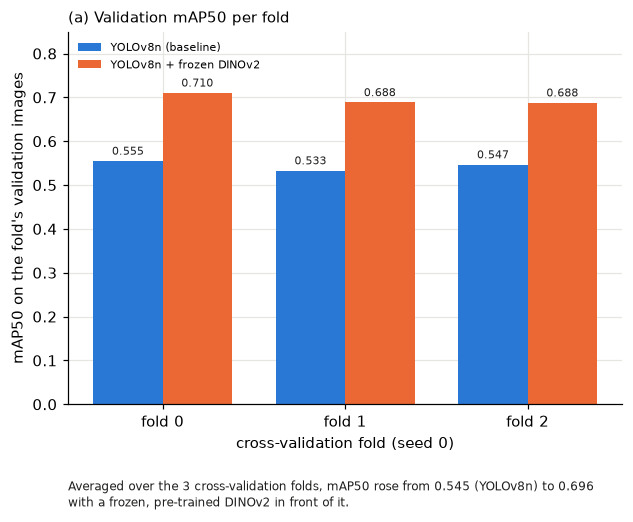

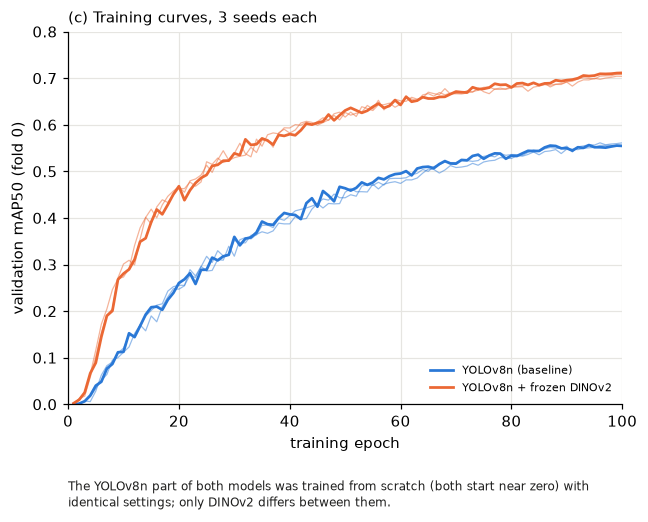

In [ ]:
# Chart helpers. Each chart is a draw_* function: shown here under its section, and reused by section 12 for the PDF.
import textwrap
from matplotlib.patches import Patch
LABEL = {"baseline": "YOLOv8n (baseline)", "dino": "YOLOv8n + frozen DINOv2", "blind": "blind control", "pretrained": "YOLOv8n from COCO weights"}

def bar_labels(ax, bars, fmt="{:.3f}", dy=0.008):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + dy, fmt.format(b.get_height()), ha="center", va="bottom", fontsize=7.5, color=INK)

def caption(ax, text, below=0.2, width=62):
    # the finding, printed under the chart it belongs to
    ax.text(0, -below, "\n".join(textwrap.wrap(text, width)), transform=ax.transAxes, va="top", ha="left", fontsize=7.8, color=INK, linespacing=1.35)

def show(draw, name, size=(6.5, 4.4)):
    # one chart on its own figure, saved to outputs/figures and shown under this cell
    fig, ax = plt.subplots(figsize=size)
    draw(ax, width=88)
    fig.savefig(OUT / "figures" / name, dpi=150, bbox_inches="tight")
    plt.show()

fold_base = statistics.mean(mAP[f"baseline-fold{f}-seed0"] for f in range(3))
fold_dino = statistics.mean(mAP[f"dino-fold{f}-seed0"] for f in range(3))

def draw_folds(ax, width=62):
    w = 0.38
    for k, a in enumerate(("baseline", "dino")):
        bar_labels(ax, ax.bar([f + (k - 0.5) * w for f in range(3)], [mAP[f"{a}-fold{f}-seed0"] for f in range(3)], w, color=COLOR[a], label=LABEL[a]))
    ax.set_xticks(range(3), [f"fold {f}" for f in range(3)])
    ax.set_xlabel("cross-validation fold (seed 0)"); ax.set_ylabel("mAP50 on the fold's validation images")
    ax.set_ylim(0, 0.85); ax.legend(frameon=False, fontsize=7.5, loc="upper left")
    ax.set_title("(a) Validation mAP50 per fold", loc="left", fontsize=10)
    caption(ax, f"Averaged over the 3 cross-validation folds, mAP50 rose from {fold_base:.3f} (YOLOv8n) to {fold_dino:.3f} "
                f"with a frozen, pre-trained DINOv2 in front of it.", below=0.2, width=width)

def draw_curves(ax, width=62):
    for a in ("baseline", "dino"):
        for s in range(3):
            with (OUT / "runs" / f"{a}-fold0-seed{s}" / "results.csv").open() as fh:
                rows = [{k.strip(): v for k, v in row.items()} for row in csv.DictReader(fh)]
            ax.plot([int(r["epoch"]) for r in rows], [float(r["metrics/mAP50(B)"]) for r in rows], color=COLOR[a],
                    lw=1.8 if s == 0 else 0.8, alpha=1 if s == 0 else 0.5, label=LABEL[a] if s == 0 else None)
    ax.set_xlabel("training epoch"); ax.set_ylabel("validation mAP50 (fold 0)")
    ax.set_xlim(0, 100); ax.set_ylim(0, 0.8); ax.legend(frameon=False, fontsize=7.5, loc="lower right")
    ax.set_title("(c) Training curves, 3 seeds each", loc="left", fontsize=10)
    caption(ax, "The YOLOv8n part of both models was trained from scratch (both start near zero) with identical settings; "
                "only DINOv2 differs between them.", below=0.2, width=width)

show(draw_folds, "a_map50_per_fold.png")
show(draw_curves, "c_training_curves.png")


## 8. Held-out test set (each model scored once)

In [ ]:
TEST_RUNS = [dict(arm=a, fold=f, seed=0) for f in range(3) for a in ("baseline", "dino")] + [dict(arm=a, fold=0, seed=0) for a in ("blind", "pretrained")]
test = {run_name(r): evaluate(r, "test") for r in TEST_RUNS}
display(pd.DataFrame(test).T[["mAP50", "mAP50_95", "precision", "recall", "f1"]].astype(float).round(3))
test_effects = [test[f"dino-fold{f}-seed0"]["mAP50"] - test[f"baseline-fold{f}-seed0"]["mAP50"] for f in range(3)]
print(f"test effects {[round(e, 4) for e in test_effects]}, mean {statistics.mean(test_effects):+.4f}")
print(f"blind - baseline {test['blind-fold0-seed0']['mAP50'] - test['baseline-fold0-seed0']['mAP50']:+.4f} | "
      f"dino - blind {test['dino-fold0-seed0']['mAP50'] - test['blind-fold0-seed0']['mAP50']:+.4f}")

,mAP50,mAP50_95,precision,recall,f1
baseline-fold0-seed0,0.545,0.341,0.607,0.508,0.547
dino-fold0-seed0,0.690,0.433,0.735,0.620,0.670
baseline-fold1-seed0,0.552,0.347,0.601,0.521,0.553
dino-fold1-seed0,0.697,0.439,0.765,0.612,0.674
baseline-fold2-seed0,0.552,0.344,0.619,0.512,0.554
dino-fold2-seed0,0.693,0.431,0.742,0.620,0.671
blind-fold0-seed0,0.543,0.341,0.595,0.507,0.542
pretrained-fold0-seed0,0.719,0.499,0.762,0.654,0.700


test effects [0.1455, 0.1449, 0.1409], mean +0.1438
blind - baseline -0.0013 | dino - blind +0.1468


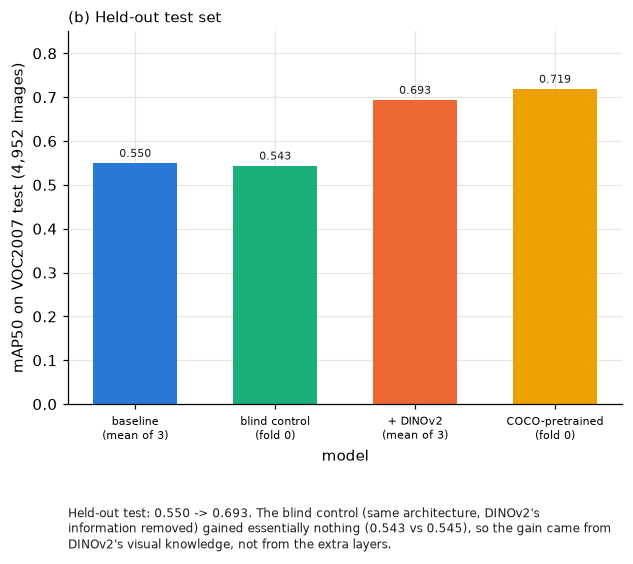

In [ ]:
test_base = [test[f"baseline-fold{f}-seed0"]["mAP50"] for f in range(3)]
test_dino = [test[f"dino-fold{f}-seed0"]["mAP50"] for f in range(3)]

def draw_test(ax, width=52):
    names = ["baseline", "blind", "dino", "pretrained"]
    vals = [statistics.mean(test_base), test["blind-fold0-seed0"]["mAP50"], statistics.mean(test_dino), test["pretrained-fold0-seed0"]["mAP50"]]
    bar_labels(ax, ax.bar(range(4), vals, 0.6, color=[COLOR[n] for n in names]))
    ax.set_xticks(range(4), ["baseline\n(mean of 3)", "blind control\n(fold 0)", "+ DINOv2\n(mean of 3)", "COCO-pretrained\n(fold 0)"], fontsize=7.5)
    ax.set_xlabel("model"); ax.set_ylabel("mAP50 on VOC2007 test (4,952 images)"); ax.set_ylim(0, 0.85)
    ax.set_title("(b) Held-out test set", loc="left", fontsize=10)
    caption(ax, f"Held-out test: {statistics.mean(test_base):.3f} -> {statistics.mean(test_dino):.3f}. The blind control (same architecture, "
                f"DINOv2's information removed) gained essentially nothing ({test['blind-fold0-seed0']['mAP50']:.3f} vs "
                f"{test['baseline-fold0-seed0']['mAP50']:.3f}), so the gain came from DINOv2's visual knowledge, not from the extra layers.",
            below=0.27, width=width)

show(draw_test, "b_test_set.png")


## 9. Why it works

In [ ]:
# Class-agnostic mAP50 scores box finding alone; the gap to normal mAP50 is what wrong class labels cost.
fold0 = OUT / "folds" / "fold0.yaml"
mech_path = OUT / "evals" / "mechanism.json"
mech = json.loads(mech_path.read_text()) if mech_path.exists() else {}
if "class_agnostic" not in mech:
    mech["class_agnostic"] = {a: {"mAP50": val[f"{a}-fold0-seed0"]["mAP50"],
                                  "single_cls": float(YOLO(str(weights(dict(arm=a, fold=0, seed=0)))).val(data=str(fold0), single_cls=True, **VAL_KW).box.map50)}
                              for a in ("baseline", "blind", "dino")}
    mech_path.write_text(json.dumps(mech, indent=2))
ca = pd.DataFrame(mech["class_agnostic"]).T
ca["lost to wrong class"] = ca["single_cls"] - ca["mAP50"]
display(ca.round(3))
gain, found = ca.loc["dino", "mAP50"] - ca.loc["baseline", "mAP50"], ca.loc["dino", "single_cls"] - ca.loc["baseline", "single_cls"]
print(f"gain {gain:+.3f}: finding objects {found:+.3f}, right class {gain - found:+.3f} ({(gain - found) / gain:.0%})")

,mAP50,single_cls,lost to wrong class
baseline,0.555,0.712,0.157
blind,0.563,0.697,0.134
dino,0.710,0.754,0.043


gain +0.155: finding objects +0.042, right class +0.114 (73%)


In [ ]:
# DINOv2 embeddings of every trainval image: near-duplicates across the fold boundary, and similarity groups.
emb_path = OUT / "trainval_embeddings.pt"
paths = sorted(str(p) for p in (VOC / "images/trainval").glob("*.jpg"))
if not emb_path.exists():
    net = Dinov2Model.from_pretrained(DINO_ID, revision=DINO_REVISION, token=False).to(DEVICE).eval().half()
    mean, std = (torch.tensor(v, device=DEVICE).view(1, 3, 1, 1) for v in (IMAGENET_MEAN, IMAGENET_STD))
    chunks = []
    with torch.no_grad():
        for i in range(0, len(paths), 64):
            x = torch.stack([F.interpolate(torch.from_numpy(np.array(Image.open(p).convert("RGB"))).permute(2, 0, 1)[None].float().div(255),
                                           size=(224, 224), mode="bilinear", antialias=True)[0] for p in paths[i:i + 64]]).to(DEVICE)
            chunks.append(F.normalize(net(pixel_values=((x - mean) / std).half()).pooler_output.float(), dim=1).cpu())
    torch.save(torch.cat(chunks), emb_path)
emb = torch.load(emb_path)
index = {p: i for i, p in enumerate(paths)}

def nearest(fold):
    tr = (OUT / "folds" / f"fold{fold}_train.txt").read_text().split()
    va = (OUT / "folds" / f"fold{fold}_val.txt").read_text().split()
    best, arg = (emb[[index[p] for p in va]] @ emb[[index[p] for p in tr]].T).max(dim=1)
    return va, best

print("near-duplicates (similarity >= 0.95) per fold:", [int((nearest(k)[1] >= 0.95).sum()) for k in range(3)])

va, best = nearest(0)
order, q = best.argsort().tolist(), len(va) // 4
if "by_similarity" not in mech:
    mech["by_similarity"] = []
    for b in range(4):
        ids = order[b * q:(b + 1) * q] if b < 3 else order[3 * q:]
        lst = OUT / "folds" / f"fold0_val_sim{b}.txt"
        lst.write_text("\n".join(va[i] for i in ids) + "\n")
        cfg = OUT / "folds" / f"fold0_sim{b}.yaml"
        cfg.write_text(fold0.read_text().replace("fold0_val.txt", lst.name))
        row = {"similarity": f"{best[ids].min():.2f}-{best[ids].max():.2f}"}
        row.update({a: float(YOLO(str(weights(dict(arm=a, fold=0, seed=0)))).val(data=str(cfg), **VAL_KW).box.map50) for a in ("baseline", "blind", "dino")})
        mech["by_similarity"].append(row)
    mech_path.write_text(json.dumps(mech, indent=2))
groups = pd.DataFrame(mech["by_similarity"]).set_index("similarity")
groups["gain"] = groups["dino"] - groups["baseline"]
display(groups.round(3))

near-duplicates (similarity >= 0.95) per fold: [7, 5, 9]


,baseline,blind,dino,gain
similarity,,,,
0.28-0.52,0.300,0.335,0.522,0.221
0.52-0.61,0.493,0.497,0.696,0.203
0.61-0.70,0.569,0.575,0.721,0.152
0.70-0.97,0.683,0.666,0.784,0.100


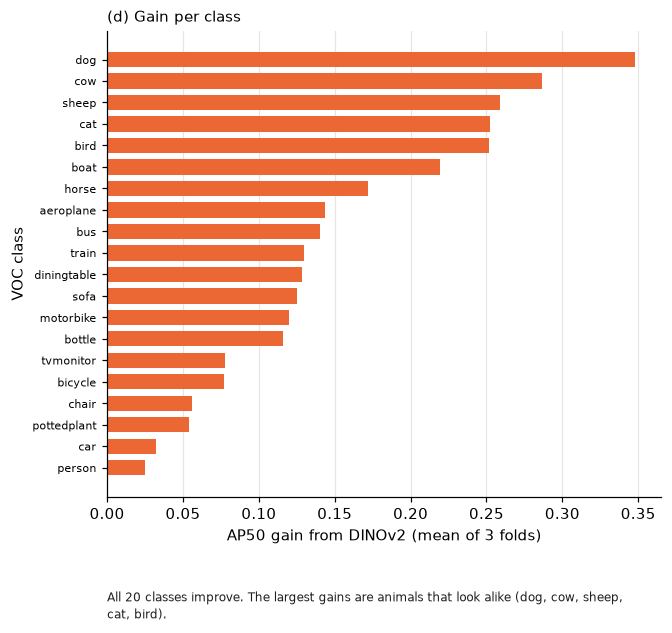

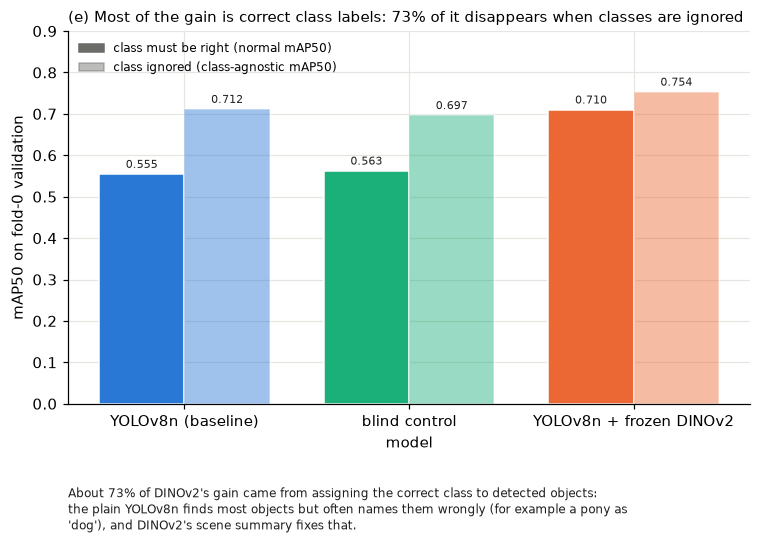

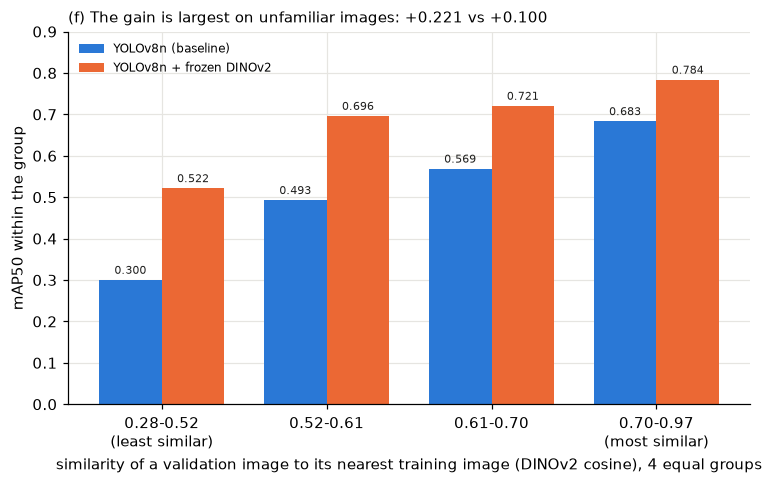

In [ ]:
per_class = {c: statistics.mean(val[f"dino-fold{f}-seed0"]["per_class_ap50"][c] - val[f"baseline-fold{f}-seed0"]["per_class_ap50"][c] for f in range(3)) for c in NAMES}
ca = mech["class_agnostic"]
ca_total = ca["dino"]["mAP50"] - ca["baseline"]["mAP50"]
ca_found = ca["dino"]["single_cls"] - ca["baseline"]["single_cls"]
cls_share = (ca_total - ca_found) / ca_total

def draw_per_class(ax, width=52):
    order = sorted(NAMES, key=per_class.get)
    ax.barh(order, [per_class[c] for c in order], color=COLOR["dino"], height=0.7)
    ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=7)
    ax.set_xlabel("AP50 gain from DINOv2 (mean of 3 folds)"); ax.set_ylabel("VOC class")
    ax.set_title("(d) Gain per class", loc="left", fontsize=10)
    caption(ax, "All 20 classes improve. The largest gains are animals that look alike (dog, cow, sheep, cat, bird).", below=0.2, width=width)

def draw_class_agnostic(ax, width=120):
    w = 0.38
    for k, (col, alpha) in enumerate((("mAP50", 1.0), ("single_cls", 0.45))):
        bar_labels(ax, ax.bar([i + (k - 0.5) * w for i in range(3)], [ca[a][col] for a in ("baseline", "blind", "dino")], w,
                              color=[COLOR[a] for a in ("baseline", "blind", "dino")], alpha=alpha, edgecolor="white"))
    ax.set_xticks(range(3), [LABEL[a] for a in ("baseline", "blind", "dino")])
    ax.set_xlabel("model"); ax.set_ylabel("mAP50 on fold-0 validation"); ax.set_ylim(0, 0.9)
    ax.legend(handles=[Patch(color=MUTED, label="class must be right (normal mAP50)"), Patch(color=MUTED, alpha=0.45, label="class ignored (class-agnostic mAP50)")],
              frameon=False, fontsize=8, loc="upper left")
    ax.set_title(f"(e) Most of the gain is correct class labels: {cls_share:.0%} of it disappears when classes are ignored", loc="left", fontsize=10)
    caption(ax, f"About {cls_share:.0%} of DINOv2's gain came from assigning the correct class to detected objects: the plain YOLOv8n finds "
                f"most objects but often names them wrongly (for example a pony as 'dog'), and DINOv2's scene summary fixes that.", below=0.22, width=width)

def draw_similarity(ax, width=120):
    w = 0.38
    for k, a in enumerate(("baseline", "dino")):
        bar_labels(ax, ax.bar([i + (k - 0.5) * w for i in range(4)], groups[a], w, color=COLOR[a], label=LABEL[a]))
    ax.set_xticks(range(4), [f"{g}\n{lab}" for g, lab in zip(groups.index, ("(least similar)", "", "", "(most similar)"))])
    ax.set_xlabel("similarity of a validation image to its nearest training image (DINOv2 cosine), 4 equal groups")
    ax.set_ylabel("mAP50 within the group"); ax.set_ylim(0, 0.9); ax.legend(frameon=False, fontsize=8, loc="upper left")
    ax.set_title(f"(f) The gain is largest on unfamiliar images: {groups['gain'].iloc[0]:+.3f} vs {groups['gain'].iloc[-1]:+.3f}", loc="left", fontsize=10)

show(draw_per_class, "d_gain_per_class.png", size=(6.5, 5.5))
show(draw_class_agnostic, "e_class_agnostic.png", size=(8, 4.4))
show(draw_similarity, "f_gain_by_similarity.png", size=(8, 4.4))


## 10. Cost

In [ ]:
# Forward pass only, fp32, 640x640: 20 warm-up passes, then the median of 100 timed passes.
@torch.no_grad()
def ms_per_image(net, batch):
    x = torch.rand(batch, 3, 640, 640, device="cuda")
    for _ in range(20):
        net(x)
    times = []
    for _ in range(100):
        torch.cuda.synchronize(); t = time.perf_counter(); net(x); torch.cuda.synchronize()
        times.append((time.perf_counter() - t) * 1000)
    return statistics.median(times) / batch

cost_path = OUT / "evals" / "cost.json"  # measured once; timings drift between runs, so reuse the first measurement
cost = json.loads(cost_path.read_text()) if cost_path.exists() else {}
for a in ("baseline", "dino", "blind", "pretrained"):
    if a in cost:
        continue
    r = dict(arm=a, fold=0, seed=0)
    net = YOLO(str(weights(r))).model.float().cuda().eval()
    cost[a] = {"params (M)": val[run_name(r)]["params_total"] / 1e6, "trainable (M)": val[run_name(r)]["params_trainable"] / 1e6,
               "GFLOPs": val[run_name(r)]["gflops_640"], "ms/img batch 1": ms_per_image(net, 1), "ms/img batch 16": ms_per_image(net, 16)}
cost_path.write_text(json.dumps(cost, indent=2))
display(pd.DataFrame(cost).T.round(2))

,params (M),trainable (M),GFLOPs,ms/img batch 1,ms/img batch 16
baseline,3.01,3.01,8.10,6.30,1.87
dino,25.27,3.21,19.29,11.76,3.78
blind,25.27,3.21,19.29,13.49,3.85
pretrained,3.01,3.01,8.10,4.88,1.86


In [ ]:
def draw_cost(ax, width=None):
    ax.axis("off"); ax.grid(False)
    rows = [[{"baseline": "YOLOv8n", "dino": "YOLOv8n + DINOv2"}[a], f"{cost[a]['params (M)']:.2f}", f"{cost[a]['trainable (M)']:.2f}",
             f"{cost[a]['GFLOPs']:.1f}", f"{cost[a]['ms/img batch 1']:.1f}", f"{cost[a]['ms/img batch 16']:.1f}"] for a in ("baseline", "dino")]
    tbl = ax.table(cellText=rows, colLabels=["model", "parameters (M)", "trainable (M)", "GFLOPs at 640 px", "ms/image, batch 1", "ms/image, batch 16"],
                   loc="center", cellLoc="center")
    tbl.auto_set_font_size(False); tbl.set_fontsize(8); tbl.scale(1, 1.6); tbl.auto_set_column_width(list(range(6)))
    ax.set_title("(g) Cost: forward pass, fp32, 640x640, RTX 4070 laptop GPU. DINOv2's 22M weights are frozen.", loc="left", fontsize=10)


## 11. Side by side

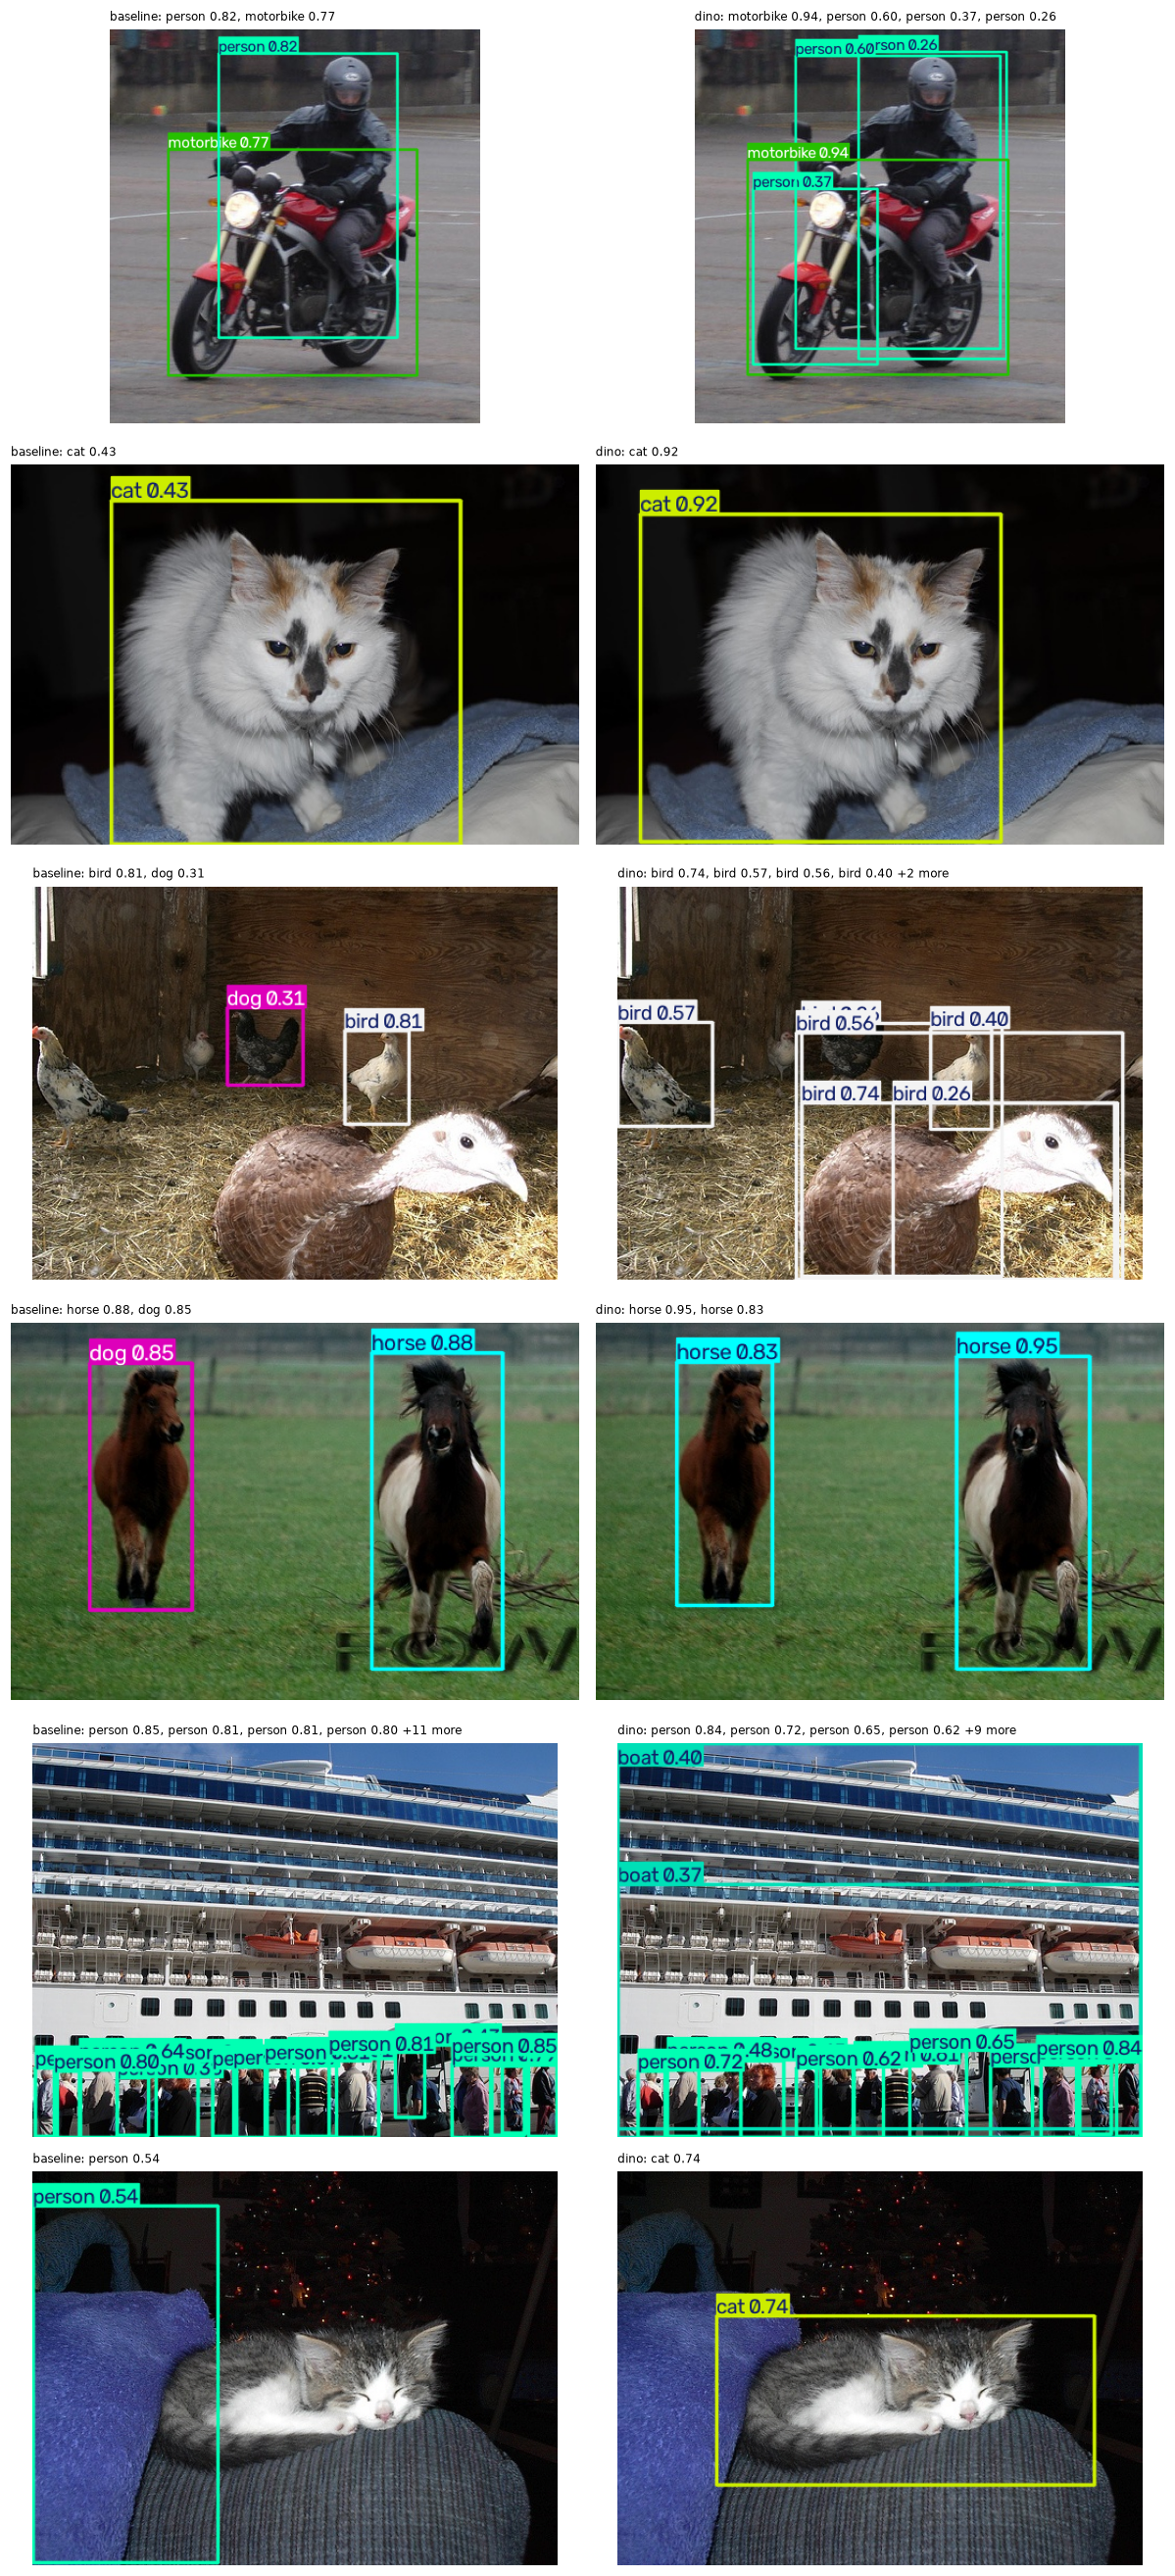

In [ ]:
models = {a: YOLO(str(weights(dict(arm=a, fold=0, seed=0)))) for a in ("baseline", "dino")}
sample = random.Random(3).sample((OUT / "folds" / "fold0_val.txt").read_text().split(), 6)
fig, axes = plt.subplots(6, 2, figsize=(11, 24))
for row, path in zip(axes, sample):
    for ax, (name, m) in zip(row, models.items()):
        res = m.predict(path, conf=0.25, imgsz=640, verbose=False)[0]
        ax.imshow(res.plot(line_width=2)[..., ::-1]); ax.axis("off"); ax.grid(False)
        found = [f"{res.names[int(c)]} {s:.2f}" for c, s in zip(res.boxes.cls, res.boxes.conf)]
        more = f" +{len(found) - 4} more" if len(found) > 4 else ""  # long lists would run into the next panel
        ax.set_title(f"{name}: " + ", ".join(found[:4]) + more, fontsize=8, loc="left")
save_fig(fig, "side_by_side.png")

## 12. Results sheet (PDF)

Assembles `assignment1_results.pdf` (three A4 pages) from the charts drawn above. Nothing is retrained or re-evaluated.

In [ ]:
from matplotlib.backends.backend_pdf import PdfPages

def page(title, subtitle):
    fig = plt.figure(figsize=(8.27, 11.69))  # A4
    fig.text(0.06, 0.965, title, fontsize=14, weight="bold", color=INK)
    fig.text(0.06, 0.945, "\n".join(textwrap.wrap(subtitle, 115)), fontsize=8.5, color=MUTED, va="top")
    return fig

p1 = page("YOLOv8n with a frozen DINOv2 in front: results on PASCAL VOC2007",
          "20 classes. 3-fold cross-validation on 5,011 trainval images; 4,952 held-out test images. Both models trained from scratch, 100 epochs, identical settings.")
verdict_text = (f"Verdict (rule fixed before training): DINOv2 helps. Mean fold gain {mean_effect:+.3f} mAP50, {mean_effect / noise:.0f}x the "
                f"seed noise ({noise:.4f}), positive on all 3 folds.")
p1.text(0.06, 0.905, "\n".join(textwrap.wrap(verdict_text, 100)), fontsize=9, color=INK, weight="bold", va="top")
gs = p1.add_gridspec(2, 2, left=0.09, right=0.97, top=0.84, bottom=0.11, hspace=0.75, wspace=0.32)
for spot, draw in ((gs[0, 0], draw_folds), (gs[0, 1], draw_test), (gs[1, 0], draw_curves), (gs[1, 1], draw_per_class)):
    draw(p1.add_subplot(spot))

p2 = page("Why DINOv2 helps, and what it costs", "Fold 0, seed 0 models, scored on fold 0's 1,670 validation images unless stated.")
gs = p2.add_gridspec(3, 1, left=0.11, right=0.95, top=0.9, bottom=0.05, hspace=0.7, height_ratios=[1, 1, 0.55])
for spot, draw in ((gs[0], draw_class_agnostic), (gs[1], draw_similarity), (gs[2], draw_cost)):
    draw(p2.add_subplot(spot))

p3 = page("Example predictions on fold-0 validation images",
          "Left: baseline. Right: + DINOv2. Confidence threshold 0.25. The baseline calls a pony and a hen 'dog' and a kitten 'person'.")
ax = p3.add_axes([0.03, 0.02, 0.94, 0.9]); ax.imshow(Image.open(OUT / "figures" / "side_by_side.png")); ax.axis("off")

pdf_path = REPO / "assignment1_results.pdf"
with PdfPages(pdf_path) as pdf:
    for i, fig in enumerate((p1, p2, p3), 1):
        pdf.savefig(fig)
        fig.savefig(OUT / "figures" / f"results_page{i}.png", dpi=110)
        plt.close(fig)
print(f"wrote {pdf_path.name}: 3 pages, {pdf_path.stat().st_size / 1e6:.1f} MB")


wrote assignment1_results.pdf: 3 pages, 0.9 MB
